In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
df = pd.read_csv("Online Retail.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
df.tail

<bound method NDFrame.tail of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

            InvoiceDate  UnitPrice  CustomerI

In [7]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541909
Columns: 8


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [10]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage.round(2))

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Value Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [11]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 5268


In [12]:
# Check cancelled invoices
cancelled_invoices = df['InvoiceNo'].astype(str).str.startswith('C').sum()

# Check returned products
returned_items = (df['Quantity'] < 0).sum()

print("Cancelled Invoice Records:", cancelled_invoices)
print("Returned Item Records:", returned_items)

Cancelled Invoice Records: 9288
Returned Item Records: 10624


In [13]:
# Calculate revenue for each transaction
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Display sample records
df[['InvoiceNo', 'Quantity', 'UnitPrice', 'Revenue']].head()

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [14]:
total_revenue = df['Revenue'].sum()

print("Total Transaction Revenue:", round(total_revenue, 2))

Total Transaction Revenue: 9747747.93


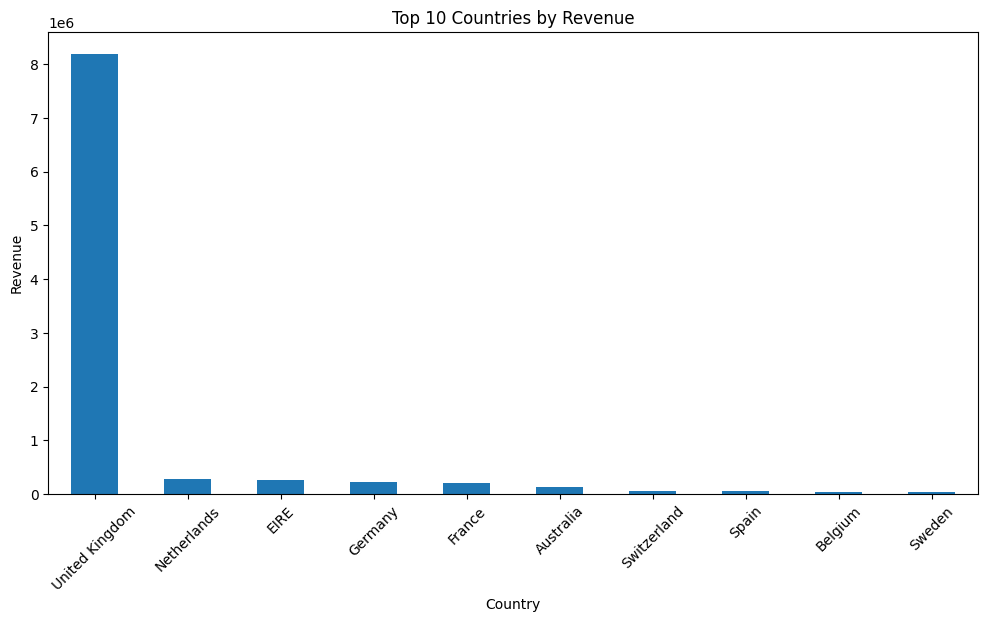

In [15]:
country_revenue = (
    df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

country_revenue.plot(kind='bar')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Country')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

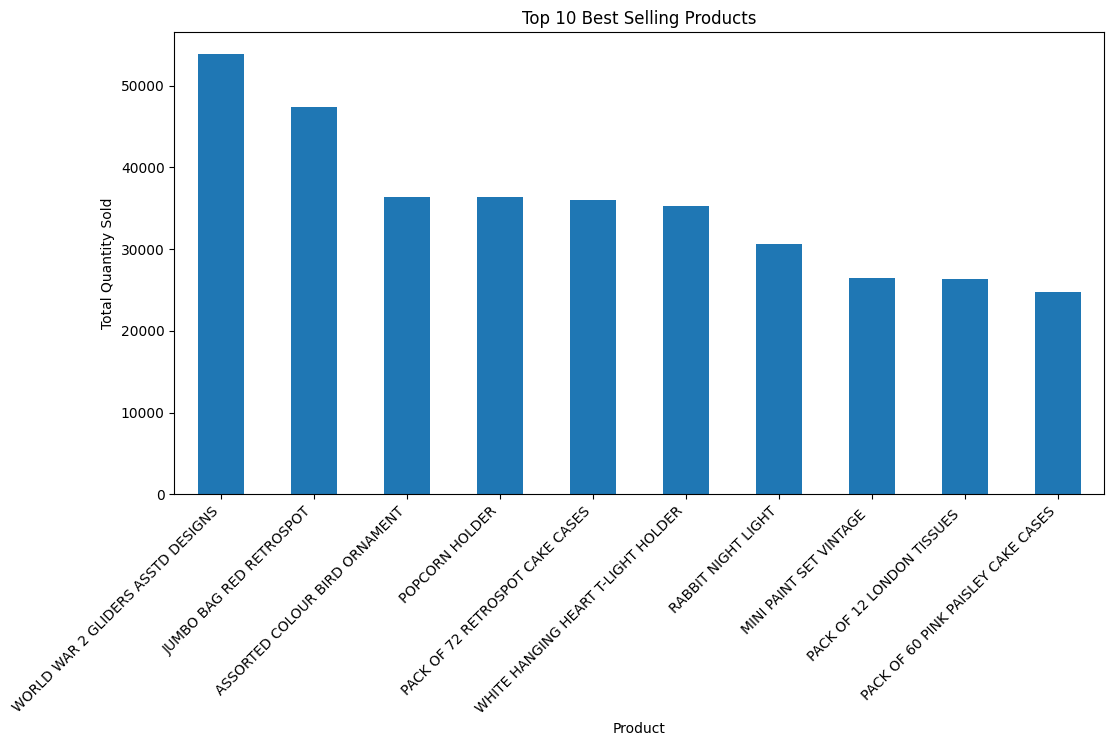

In [16]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_products.plot(kind='bar')

plt.title('Top 10 Best Selling Products')
plt.xlabel('Product')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45, ha='right')

plt.show()

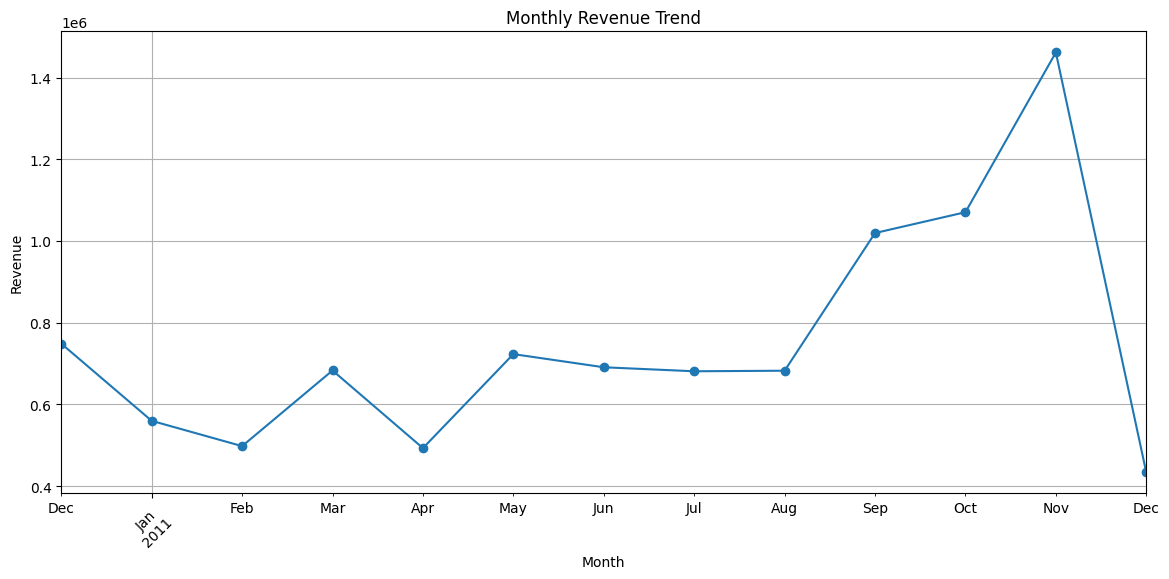

In [17]:
# Convert InvoiceDate into datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract month
df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_revenue = df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(14, 6))

monthly_revenue.plot(marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

In [18]:
#Data cleaning
# Create a working copy
clean_df = df.copy()

print("Original dataset shape:", clean_df.shape)

Original dataset shape: (541909, 10)


In [19]:
# Remove duplicate transactions
clean_df = clean_df.drop_duplicates()

print("Shape after removing duplicates:", clean_df.shape)

Shape after removing duplicates: (536641, 10)


In [20]:
clean_df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Revenue             0
Month               0
dtype: int64

In [21]:
# Remove records without essential product or date information
clean_df = clean_df.dropna(subset=['StockCode', 'InvoiceDate'])

print("Shape after handling essential missing values:", clean_df.shape)

Shape after handling essential missing values: (536641, 10)


In [22]:
# Remove cancelled invoices
clean_df = clean_df[
    ~clean_df['InvoiceNo'].astype(str).str.startswith('C')
]

print("Shape after removing cancellations:", clean_df.shape)

Shape after removing cancellations: (527390, 10)


In [23]:
# Keep only valid positive sales
clean_df = clean_df[
    (clean_df['Quantity'] > 0) &
    (clean_df['UnitPrice'] > 0)
]

print("Shape after removing returns and invalid transactions:", clean_df.shape)

Shape after removing returns and invalid transactions: (524878, 10)


In [24]:
# Calculate revenue
clean_df['Revenue'] = (
    clean_df['Quantity'] * clean_df['UnitPrice']
)

clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [25]:
# Ensure InvoiceDate is datetime
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'])

# Extract date features
clean_df['Date'] = clean_df['InvoiceDate'].dt.date
clean_df['Year'] = clean_df['InvoiceDate'].dt.year
clean_df['Month'] = clean_df['InvoiceDate'].dt.month
clean_df['Day'] = clean_df['InvoiceDate'].dt.day
clean_df['DayOfWeek'] = clean_df['InvoiceDate'].dt.dayofweek

clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Date,Year,Day,DayOfWeek
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010-12-01,2010,1,2
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010-12-01,2010,1,2
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010-12-01,2010,1,2
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010-12-01,2010,1,2
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010-12-01,2010,1,2


In [26]:
print("Final cleaned dataset shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nDuplicate records:", clean_df.duplicated().sum())

print("\nTotal Revenue:", round(clean_df['Revenue'].sum(), 2))

print("\nDate Range:")
print(clean_df['InvoiceDate'].min())
print(clean_df['InvoiceDate'].max())

Final cleaned dataset shape: (524878, 14)

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Month               0
Date                0
Year                0
Day                 0
DayOfWeek           0
dtype: int64

Duplicate records: 0

Total Revenue: 10642110.8

Date Range:
2010-12-01 08:26:00
2011-12-09 12:50:00
